# C. FCN(1D-CNN) + center loss — 분류 21-fold, 임베딩 147-fold

- 할 일
  1. 녹화 하나 빼기 21-fold로 재질 8종 분류 성능을 낸다 (MiniRocket·B 고전 모델과 비교)
  2. center loss 유무를 비교한다 (팀 2×2 ablation 중 C가 맡은 축)
  3. 재질 하나 빼기 147-fold마다 모델을 학습해 임베딩·logits를 저장한다 → D(미등록 판별)·E(신규 등록)가 사용
- 모델: FCN (Wang et al., 2017, IJCNN). 시계열 분류에서 딥러닝 기준선으로 가장 많이 쓰는 구조
- center loss: Wen et al., 2016, ECCV
- 런타임: **GPU 필요** (런타임 → 런타임 유형 변경 → T4 GPU)
- Colab이 끊겨도 이어서 돌 수 있게, 튜닝 결과·임베딩·학습 기록을 구글 드라이브에 바로바로 저장한다

순서: 0~2 준비 → 3 시간 재기 → 4 튜닝 → 5 분류 21-fold → 6 임베딩 147-fold → 7 기록 정리

## 0. 환경 준비

In [1]:
import os
import sys
import json
import time
import shutil
import subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/ML-imu").exists():
        !git clone -q https://github.com/ekgP525/ML-imu.git /content/ML-imu
    os.chdir("/content/ML-imu")
    !pip install -q -r requirements.txt

    # 데이터 준비: ① 드라이브 사본 → 없으면 ② Zenodo에서 파일 직접 받기
    # (팀 download.py는 Zenodo 응답이 30초를 넘으면 실패해서, 기다리는 시간을 늘리고 재시도한다)
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE = Path("/content/drive/MyDrive/ML-imu/data_cache")
    CACHE.mkdir(parents=True, exist_ok=True)
    DATA_FILES = {"X_data.npy": 78090368, "label.npy": 61136,
                  "groups.npy": 61136, "details.csv": 128466}   # 파일 이름: 정상 크기(바이트)
    ok = lambda f, size: f.exists() and f.stat().st_size == size
    for name, size in DATA_FILES.items():
        dest = Path("data") / name
        if ok(dest, size):
            continue
        if ok(CACHE / name, size):
            shutil.copy(CACHE / name, dest)
            print("드라이브 사본 사용:", name)
            continue
        url = f"https://zenodo.org/records/2653918/files/{name}?download=1"
        subprocess.run(["wget", "-q", "--tries=5", "--timeout=120", "-O", str(dest), url])
        if not ok(dest, size):
            raise RuntimeError(f"{name} 다운로드 실패 (Zenodo가 느림) → 이 셀을 다시 실행하세요")
        shutil.copy(dest, CACHE / name)
        print("Zenodo에서 받음 + 드라이브에 사본 저장:", name)
    print("데이터 준비 완료")

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.append(str(ROOT / "src"))
print("레포 위치:", ROOT)

Mounted at /content/drive
Zenodo에서 받음 + 드라이브에 사본 저장: X_data.npy
Zenodo에서 받음 + 드라이브에 사본 저장: label.npy
Zenodo에서 받음 + 드라이브에 사본 저장: groups.npy
Zenodo에서 받음 + 드라이브에 사본 저장: details.csv
데이터 준비 완료
레포 위치: /content/ML-imu


저장 위치: 임베딩은 레포에 올리지 않고 드라이브에 둔다 (README 규칙)

- 팀 공유 폴더를 쓰려면: 드라이브에서 공유 폴더 → 오른쪽 클릭 → "바로가기 추가" → 내 드라이브. 그러면 `/content/drive/MyDrive/폴더이름`으로 보인다
- 아래 `OUT_DIR`을 그 경로로 바꾼다

In [2]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/ML-imu/embeddings")   # ← 팀 공유 폴더 경로로 바꾸기
else:
    OUT_DIR = ROOT / "embeddings"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("저장 위치:", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
저장 위치: /content/drive/MyDrive/ML-imu/embeddings


## 1. 데이터와 분할

- `X` (7626, 128, 6): 구간 × 시간 × 채널(각속도 3 + 가속도 3), `y`: 재질 8종, `rec`: 녹화 번호 0~20
- `folds`: 녹화 하나 빼기 21개. 분류 성능용
- `mfolds`: 재질 하나 빼기 147개. 재질 m을 학습에서 통째로 빼고(= 미등록 바닥 역할), 남은 재질의 녹화 하나를 시험용(알려진 바닥)으로 뗀다
  - 재질 8종 × 남은 녹화 수(17~19) = 147

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score, confusion_matrix

from recordings import load_dataset, CLASSES
from splits import load_folds, load_material_folds, fold_indices, inner_val_recordings
from preprocess import normalize
from evaluate import evaluate, log_result, to_mode

SEED = 42
torch.backends.cudnn.deterministic = True    # 같은 seed면 같은 결과가 나오게
torch.backends.cudnn.benchmark = False
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU 없음 → 런타임 → 런타임 유형 변경 → T4 GPU 로 바꾸고 다시 실행")

X, y, rec = load_dataset(str(ROOT / "data"))
folds = load_folds()
mfolds = load_material_folds()
print("X", X.shape, "| 녹화 하나 빼기", len(folds), "| 재질 하나 빼기", len(mfolds))

GPU: Tesla T4
X (7626, 128, 6) | 녹화 하나 빼기 21 | 재질 하나 빼기 147


## 2. 모델과 loss

### FCN 구조 (Wang et al., 2017 그대로)

```
입력 (6채널 × 128스텝)
→ 합성곱 블록 1: 필터 128개, 길이 8 → BatchNorm → ReLU
→ 합성곱 블록 2: 필터 256개, 길이 5 → BatchNorm → ReLU
→ 합성곱 블록 3: 필터 128개, 길이 3 → BatchNorm → ReLU
→ 전역 평균 풀링: 시간 축 128칸을 평균 → 숫자 128개 = 임베딩 z
→ 선형층 → 재질별 점수(logits) → softmax
```

- 합성곱 필터: 진동 신호 위를 미끄러지며 "이 모양이 있나"를 찾는 작은 패턴 탐지기. MiniRocket은 정해진 필터를 쓰고, FCN은 필터 모양을 학습한다
- 풀링·dropout 없이 `padding="same"`으로 길이를 유지한다 (원 논문 설정)
- **임베딩 z**: 구간 하나를 숫자 128개로 요약한 것. 비슷한 바닥이면 z끼리 가깝다 → D는 이 거리로 미등록을 판별하고, E는 새 재질의 z 평균(프로토타입)으로 등록한다
- **logits**: 재질별 점수. D의 softmax 최대 확률(MSP)·Energy 점수에 쓴다

### loss

- 기본: 교차 엔트로피(CE). 정답 재질의 확률을 높인다
- center loss: `L = CE + λ · ½ · 평균‖z − c_y‖²`
  - `c_y`: 재질 y의 임베딩 중심. 배치마다 그 재질 구간들 쪽으로 조금씩 옮긴다 (Wen et al.의 중심 갱신 규칙, α = 0.5)
  - CE만 쓰면 재질끼리 "선으로 나뉘기만" 하면 되고, 같은 재질 안 임베딩은 넓게 퍼져도 된다
  - center loss는 같은 재질 임베딩을 중심으로 모은다 → 재질 덩어리가 촘촘해진다 → 어느 덩어리에서도 먼 구간 = 미등록 바닥으로 판별하기 쉬워진다는 게 팀 가설
  - λ: 모으는 힘의 세기. 너무 크면 임베딩이 한 점으로 뭉개진다 → 검증 녹화로 고른다(4번)

In [4]:
EMB_DIM = 128


class FCN(nn.Module):
    def __init__(self, in_ch, n_classes):
        super().__init__()

        def block(c_in, c_out, k):
            return nn.Sequential(nn.Conv1d(c_in, c_out, k, padding="same"),
                                 nn.BatchNorm1d(c_out), nn.ReLU())

        self.features = nn.Sequential(block(in_ch, 128, 8), block(128, 256, 5), block(256, EMB_DIM, 3))
        self.head = nn.Linear(EMB_DIM, n_classes)

    def forward(self, x):                   # x: (배치, 6, 128)
        z = self.features(x).mean(dim=2)    # 전역 평균 풀링 → (배치, 128)
        return z, self.head(z)              # 임베딩, logits


def center_loss(z, y_idx, centers):
    """½ · 평균 ‖z − c_y‖² (중심 쪽으로는 기울기를 흘리지 않음)."""
    return 0.5 * ((z - centers[y_idx]) ** 2).sum(dim=1).mean()


@torch.no_grad()
def update_centers(centers, z, y_idx, alpha=0.5):
    """Wen et al., 2016 중심 갱신: c_j ← c_j − α · Σ_{i∈j}(c_j − z_i) / (1 + n_j)."""
    n = torch.bincount(y_idx, minlength=len(centers)).float()[:, None]
    s = torch.zeros_like(centers).index_add_(0, y_idx, z)
    centers -= alpha * (n * centers - s) / (1 + n)


m = FCN(6, 8)
print(m)
print("파라미터 수:", sum(p.numel() for p in m.parameters()))

FCN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv1d(6, 128, kernel_size=(8,), stride=(1,), padding=same)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (1): Sequential(
      (0): Conv1d(128, 256, kernel_size=(5,), stride=(1,), padding=same)
      (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (2): Sequential(
      (0): Conv1d(256, 128, kernel_size=(3,), stride=(1,), padding=same)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
  )
  (head): Linear(in_features=128, out_features=8, bias=True)
)
파라미터 수: 270856


### 학습 함수

- 최적화: Adam, 학습률 0.001, 배치 64, epoch 수는 4번 튜닝으로 정한다
- 정규화: 학습 녹화의 채널별 평균·표준편차로만 (A의 `normalize`)
- 데이터가 작아서(구간 약 7천 개) 전부 GPU에 올려 두고 섞어서 잘라 쓴다
- `train_model`이 돌려주는 기록: epoch마다 걸린 초, 학습 CE, 학습 center loss, (검증 녹화를 주면) 검증 macro-F1·정확도

In [5]:
LR = 1e-3
BATCH = 64
ALPHA = 0.5


def to_input(x):
    """(N, 128, 6) → (N, 6, 128). Conv1d는 (배치, 채널, 시간) 순서를 받는다."""
    return np.ascontiguousarray(x.transpose(0, 2, 1), dtype=np.float32)


@torch.no_grad()
def embed(model, x, bs=1024):
    """구간들의 임베딩 z와 logits를 numpy로 돌려준다."""
    model.eval()
    zs, ls = [], []
    for b in range(0, len(x), bs):
        z, l = model(torch.from_numpy(x[b:b + bs]).to(DEVICE))
        zs.append(z.cpu())
        ls.append(l.cpu())
    return torch.cat(zs).numpy(), torch.cat(ls).numpy()


def train_model(x_tr, y_tr, classes, lam, epochs, x_val=None, y_val=None):
    torch.manual_seed(SEED)
    lookup = {c: i for i, c in enumerate(classes)}
    xt = torch.from_numpy(x_tr).to(DEVICE)
    yt = torch.tensor([lookup[c] for c in y_tr], device=DEVICE)
    model = FCN(xt.shape[1], len(classes)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    centers = torch.zeros(len(classes), EMB_DIM, device=DEVICE)
    gen = torch.Generator().manual_seed(SEED)
    hist = []
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        model.train()
        perm = torch.randperm(len(xt), generator=gen).to(DEVICE)
        sum_ce = torch.zeros((), device=DEVICE)
        sum_c = torch.zeros((), device=DEVICE)
        for b in range(0, len(xt), BATCH):
            idx = perm[b:b + BATCH]
            if len(idx) < 2:            # BatchNorm은 구간 1개짜리 배치를 못 받는다
                continue
            z, logits = model(xt[idx])
            ce = F.cross_entropy(logits, yt[idx])
            loss = ce
            if lam > 0:
                c = center_loss(z, yt[idx], centers)
                loss = ce + lam * c
                sum_c += c.detach() * len(idx)
            opt.zero_grad()
            loss.backward()
            opt.step()
            if lam > 0:
                update_centers(centers, z.detach(), yt[idx], ALPHA)
            sum_ce += ce.detach() * len(idx)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        row = {"epoch": ep, "sec": time.perf_counter() - t0,
               "train_ce": sum_ce.item() / len(xt), "train_center": sum_c.item() / len(xt)}
        if x_val is not None:
            _, lv = embed(model, x_val)
            pred = np.array(classes)[lv.argmax(1)]
            row["val_macro_f1"] = f1_score(y_val, pred, labels=np.unique(y_val), average="macro")
            row["val_acc"] = float(np.mean(pred == y_val))
        hist.append(row)
    return model, pd.DataFrame(hist)


LOG_PATH = OUT_DIR / "train_log.csv"


def log_train(**row):
    """학습 1회마다 드라이브의 train_log.csv에 한 줄 추가 (진행 기록용: 시간·횟수·loss)."""
    row = {"date": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), **row}
    pd.DataFrame([row]).to_csv(LOG_PATH, mode="a", header=not LOG_PATH.exists(), index=False)

## 3. 1 epoch 시간 재기

- fold 0으로 4 epoch만 돌린다. 첫 epoch는 GPU 준비 때문에 느려서 빼고 평균
- 이 숫자로 전체 작업 시간을 미리 계산한다 → 너무 길면 D와 fold 수를 줄일지 상의

In [6]:
MAX_EPOCHS = 100                      # 튜닝 때 지켜볼 최대 epoch
LAMBDAS = [0.0, 0.001, 0.01, 0.1]     # 0.0 = center loss 없음(CE만)
TUNE_FOLDS = list(range(0, 21, 4))    # 시간을 아끼려고 21개 중 6개 fold(0, 4, 8, 12, 16, 20)에서만 튜닝

tr, te = fold_indices(folds[0], rec)
x_tr, stats = normalize(X[tr])
_, h = train_model(to_input(x_tr), y[tr], CLASSES, lam=0.0, epochs=4)
SEC_PER_EPOCH = h.sec.iloc[1:].mean()
print(h.round(3).to_string(index=False))
print(f"\n1 epoch ≈ {SEC_PER_EPOCH:.2f}초 (학습 구간 {len(tr)}개, 배치 {BATCH})")

n_tune = len(TUNE_FOLDS) * len(LAMBDAS)
n_loro = 2 * len(folds)
n_mout = 2 * len(mfolds)
for name, n in [("튜닝", n_tune), ("분류 21-fold × 2", n_loro), ("임베딩 147-fold × 2", n_mout)]:
    print(f"{name:<18} 학습 {n:3d}번 × 최대 {MAX_EPOCHS} epoch ≈ 최대 {n * MAX_EPOCHS * SEC_PER_EPOCH / 3600:.1f}시간")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/conv.py:380: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1104.)
  return F.conv1d(


 epoch   sec  train_ce  train_center
     1 2.534     1.437           0.0
     2 0.683     1.250           0.0
     3 0.681     1.145           0.0
     4 0.682     1.056           0.0

1 epoch ≈ 0.68초 (학습 구간 7323개, 배치 64)
튜닝                 학습  24번 × 최대 100 epoch ≈ 최대 0.5시간
분류 21-fold × 2     학습  42번 × 최대 100 epoch ≈ 최대 0.8시간
임베딩 147-fold × 2   학습 294번 × 최대 100 epoch ≈ 최대 5.6시간


## 4. 튜닝: epoch 수와 λ 고르기

- 시험 녹화는 절대 보지 않는다. fold마다 **학습 녹화 안에서** 검증 녹화를 떼어(`inner_val_recordings`, 재질별로 녹화가 2개 이상 남으면 1개) 남은 녹화로 학습하고 검증 녹화로 채점한다
- λ 4개 × 튜닝 fold 6개 = 학습 24번. epoch마다 검증 macro-F1을 기록한다
- 고르는 법: 튜닝 fold 6개 평균 곡선을 5 epoch 이동평균으로 부드럽게 한 뒤 가장 높은 지점
  - CE만(`fcn`): λ = 0에서 가장 좋은 epoch
  - center loss(`fcn-center`): λ > 0 중 가장 좋은 λ와 그 epoch
- 한 번 학습할 때마다 드라이브에 저장 → 끊기면 다시 실행해도 끝난 것은 건너뛴다
- 한계: 고른 값을 21개 fold 모두에 쓰므로, 엄밀히는 fold마다 따로 고르는 중첩 교차검증보다 약하다. 고르는 값이 2개(epoch, λ)뿐이라 영향은 작다고 보고 한계로 적는다

In [7]:
TUNE_PATH = OUT_DIR / "fcn_tuning.csv"
done = set()
if TUNE_PATH.exists():
    old = pd.read_csv(TUNE_PATH)
    done = set(zip(old["fold"], old["lam"]))
    print("이미 끝난 튜닝:", len(done), "개")

for fid in TUNE_FOLDS:
    fold = folds[fid]
    val_recs = inner_val_recordings(fold["train"], y, rec)
    fit_recs = [r for r in fold["train"] if r not in val_recs]
    fit = np.where(np.isin(rec, fit_recs))[0]
    val = np.where(np.isin(rec, val_recs))[0]
    x_fit, stats = normalize(X[fit])
    x_val = normalize(X[val], stats)
    for lam in LAMBDAS:
        if (fid, lam) in done:
            continue
        t0 = time.perf_counter()
        _, h = train_model(to_input(x_fit), y[fit], CLASSES, lam, MAX_EPOCHS, to_input(x_val), y[val])
        h["fold"], h["lam"] = fid, lam
        h.to_csv(TUNE_PATH, mode="a", header=not TUNE_PATH.exists(), index=False)
        log_train(model="fcn-tuning", split="inner-validation", held_out="none", fold=fid,
                  n_train=len(fit), epochs=MAX_EPOCHS, lam=lam, sec=round(time.perf_counter() - t0, 1),
                  sec_per_epoch=round(h.sec.mean(), 3), final_train_ce=round(h.train_ce.iloc[-1], 4),
                  final_train_center=round(h.train_center.iloc[-1], 4))
        print(f"fold {fid:2d} | 검증 녹화 {val_recs} | λ={lam:<6} | 마지막 검증 macro-F1 "
              f"{h.val_macro_f1.iloc[-1]:.3f} | {time.perf_counter() - t0:.0f}초")

tune_df = pd.read_csv(TUNE_PATH)

이미 끝난 튜닝: 24 개


       best_val_macro_f1  best_epoch
lam                                 
0.000              0.374          69
0.001              0.372          69
0.010              0.367          70
0.100              0.357          88

선택: {'fcn': {'lam': 0.0, 'epochs': 69}, 'fcn-center': {'lam': 0.1, 'epochs': 88}}


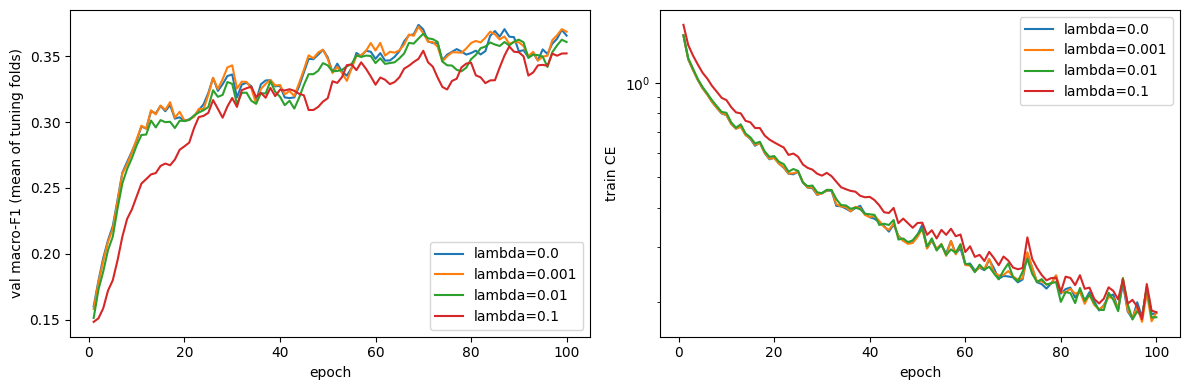

In [8]:
curve = tune_df.pivot_table(index="epoch", columns="lam", values="val_macro_f1", aggfunc="mean")
smooth = curve.rolling(5, min_periods=1).mean()

# center loss의 λ: 분류 점수로만 고르면 항상 가장 약한 λ가 뽑힌다(0.001은 λ=0과 곡선이 거의 같음).
# center loss의 목적은 D의 미등록 판별이므로, 분류 하락이 작은(0.374 → 0.357) 0.1로 정함 (11/24 튜닝 곡선 보고 결정)
best_lam = 0.1
config = {
    "fcn": {"lam": 0.0, "epochs": int(smooth[0.0].idxmax())},
    "fcn-center": {"lam": float(best_lam), "epochs": int(smooth[best_lam].idxmax())},
}
(OUT_DIR / "fcn_config.json").write_text(json.dumps(config, indent=2))
print(pd.DataFrame({"best_val_macro_f1": smooth.max().round(3), "best_epoch": smooth.idxmax()}))
print("\n선택:", config)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for lam in smooth.columns:
    axes[0].plot(smooth.index, smooth[lam], label=f"lambda={lam}")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("val macro-F1 (mean of tuning folds)")
axes[0].legend()
train_curve = tune_df.pivot_table(index="epoch", columns="lam", values="train_ce", aggfunc="mean")
for lam in train_curve.columns:
    axes[1].plot(train_curve.index, train_curve[lam], label=f"lambda={lam}")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("train CE")
axes[1].set_yscale("log")
axes[1].legend()
plt.tight_layout()
plt.show()

### 곡선 읽는 법

- 왼쪽(검증 macro-F1): 올라가다 평평해지거나 내려가는 지점이 적당한 epoch. 계속 내려가면 학습 녹화에 과적합
- 오른쪽(학습 CE): 0에 가깝게 계속 내려가는데 검증은 안 오르면 → 녹화 자체를 외우는 중
- λ가 커질수록 검증이 확 떨어지면 임베딩이 뭉개진 것 → 그 λ는 너무 큼

## 5. 분류: 녹화 하나 빼기 21-fold

- `fcn`(CE만)과 `fcn-center`(+center loss) 각각 21번 학습 → 21개 fold 예측을 모아 한 번에 평가
- 결과는 `results/results.csv`에 기록 (MiniRocket과 같은 표에서 비교)
- 시험 구간의 임베딩도 모아서 `emb_{모델}_none_all.npy`로 저장 (E의 t-SNE 등에 사용 가능)

In [9]:
def run_loro(name):
    cfg = config[name]
    y_pred = np.empty(len(y), dtype=object)
    Z = np.zeros((len(y), EMB_DIM), np.float32)
    L = np.zeros((len(y), len(CLASSES)), np.float32)
    rows = []
    t_all = time.perf_counter()
    for fold in folds:
        tr, te = fold_indices(fold, rec)
        x_tr, stats = normalize(X[tr])
        x_te = normalize(X[te], stats)
        t0 = time.perf_counter()
        model, h = train_model(to_input(x_tr), y[tr], CLASSES, cfg["lam"], cfg["epochs"])
        sec = time.perf_counter() - t0
        # E용: 이 fold 모델로 전체 7,626구간 임베딩 저장 (B의 emb_mlp_none_{fold}.npy와 같은 형식)
        z_all, l_all = embed(model, to_input(normalize(X, stats)))
        np.save(OUT_DIR / f"emb_{name}_none_{fold['fold']}.npy", z_all)
        np.save(OUT_DIR / f"logits_{name}_none_{fold['fold']}.npy", l_all)
        z, l = z_all[te], l_all[te]
        Z[te], L[te] = z, l
        y_pred[te] = np.array(CLASSES)[l.argmax(1)]
        acc = float(np.mean(y_pred[te] == y[te]))
        wrong = pd.Series(y_pred[te][y_pred[te] != y[te]])
        rows.append({"fold": fold["fold"], "test_rec": fold["test"][0], "surface": y[te][0],
                     "segments": len(te), "accuracy": round(acc, 3),
                     "mostly_confused_with": wrong.mode().iloc[0] if len(wrong) else "-",
                     "sec": round(sec, 1)})
        log_train(model=name, split="leave-one-recording-out", held_out="none", fold=fold["fold"],
                  n_train=len(tr), epochs=cfg["epochs"], lam=cfg["lam"], sec=round(sec, 1),
                  sec_per_epoch=round(h.sec.mean(), 3), final_train_ce=round(h.train_ce.iloc[-1], 4),
                  final_train_center=round(h.train_center.iloc[-1], 4))
        print(f"[{name}] fold {fold['fold']:2d} | 녹화 {fold['test'][0]:2d} {y[te][0]:<13} "
              f"| 정확도 {acc:.3f} | {sec:5.1f}초")
    assert not any(p is None for p in y_pred)
    np.save(OUT_DIR / f"emb_{name}_none_all.npy", Z)
    np.save(OUT_DIR / f"logits_{name}_none_all.npy", L)
    total = time.perf_counter() - t_all
    print(f"[{name}] 전체 {total / 60:.1f}분")
    return y_pred.astype(str), pd.DataFrame(rows), total


results = {}
for name in ["fcn", "fcn-center"]:
    y_pred, per_fold, total = run_loro(name)
    met = evaluate(y, y_pred)
    met_mode_acc = float(np.mean(to_mode(y) == to_mode(y_pred)))
    cfg = config[name]
    log_result("C", name, met, setting="8class", fold="all",
               note=f"FCN lam={cfg['lam']} epochs={cfg['epochs']} batch={BATCH} lr={LR}, 6ch, "
                    f"total {total / 60:.1f}min")
    results[name] = {"pred": y_pred, "per_fold": per_fold, "metrics": met, "mode_acc": met_mode_acc}

[fcn] fold  0 | 녹화  0 hard_tiles    | 정확도 0.059 |  51.3초
[fcn] fold  1 | 녹화  1 soft_pvc      | 정확도 0.351 |  53.1초
[fcn] fold  2 | 녹화  2 soft_tiles    | 정확도 0.003 |  53.3초
[fcn] fold  3 | 녹화  3 fine_concrete | 정확도 0.041 |  53.6초
[fcn] fold  4 | 녹화  4 concrete      | 정확도 0.228 |  53.9초
[fcn] fold  5 | 녹화  5 soft_pvc      | 정확도 0.000 |  52.5초
[fcn] fold  6 | 녹화  6 hard_tiles    | 정확도 0.318 |  51.2초
[fcn] fold  7 | 녹화  7 carpet        | 정확도 0.703 |  54.3초
[fcn] fold  8 | 녹화  8 tiled         | 정확도 0.004 |  53.4초
[fcn] fold  9 | 녹화  9 fine_concrete | 정확도 0.078 |  51.2초
[fcn] fold 10 | 녹화 10 soft_pvc      | 정확도 0.774 |  54.4초
[fcn] fold 11 | 녹화 11 soft_tiles    | 정확도 0.106 |  53.8초
[fcn] fold 12 | 녹화 12 tiled         | 정확도 0.849 |  52.1초
[fcn] fold 13 | 녹화 13 soft_pvc      | 정확도 0.383 |  53.4초
[fcn] fold 14 | 녹화 14 wood          | 정확도 0.543 |  54.4초
[fcn] fold 15 | 녹화 15 carpet        | 정확도 0.828 |  52.8초
[fcn] fold 16 | 녹화 16 concrete      | 정확도 0.059 |  52.0초
[fcn] fold 17 | 녹화 17 tiled    

In [10]:
summary_tbl = pd.DataFrame({name: {**r["metrics"], "mode_accuracy": r["mode_acc"]}
                            for name, r in results.items()}).T.astype(float).round(4)
print(summary_tbl)
print("(모드 정확도 기준선: 전부 '딱딱한 바닥'이면 0.663)")

per_fold_cmp = results["fcn"]["per_fold"][["fold", "test_rec", "surface", "segments", "accuracy"]].rename(
    columns={"accuracy": "acc_fcn"})
per_fold_cmp["acc_fcn_center"] = results["fcn-center"]["per_fold"]["accuracy"].values
per_fold_cmp["diff"] = (per_fold_cmp.acc_fcn_center - per_fold_cmp.acc_fcn).round(3)
per_fold_cmp

            macro_f1  accuracy  mode_macro_f1  mode_accuracy
fcn           0.2887    0.3025         0.6983         0.7309
fcn-center    0.2816    0.3061         0.6880         0.7292
(모드 정확도 기준선: 전부 '딱딱한 바닥'이면 0.663)


,fold,test_rec,surface,segments,acc_fcn,acc_fcn_center,diff
0,0,0,hard_tiles,303,0.059,0.314,0.255
1,1,1,soft_pvc,362,0.351,0.635,0.284
2,2,2,soft_tiles,287,0.003,0.000,-0.003
3,3,3,fine_concrete,243,0.041,0.160,0.119
4,4,4,concrete,219,0.228,0.260,0.032
5,5,5,soft_pvc,404,0.000,0.002,0.002
6,6,6,hard_tiles,576,0.318,0.035,-0.283
7,7,7,carpet,172,0.703,0.698,-0.005
8,8,8,tiled,273,0.004,0.000,-0.004
9,9,9,fine_concrete,578,0.078,0.016,-0.062


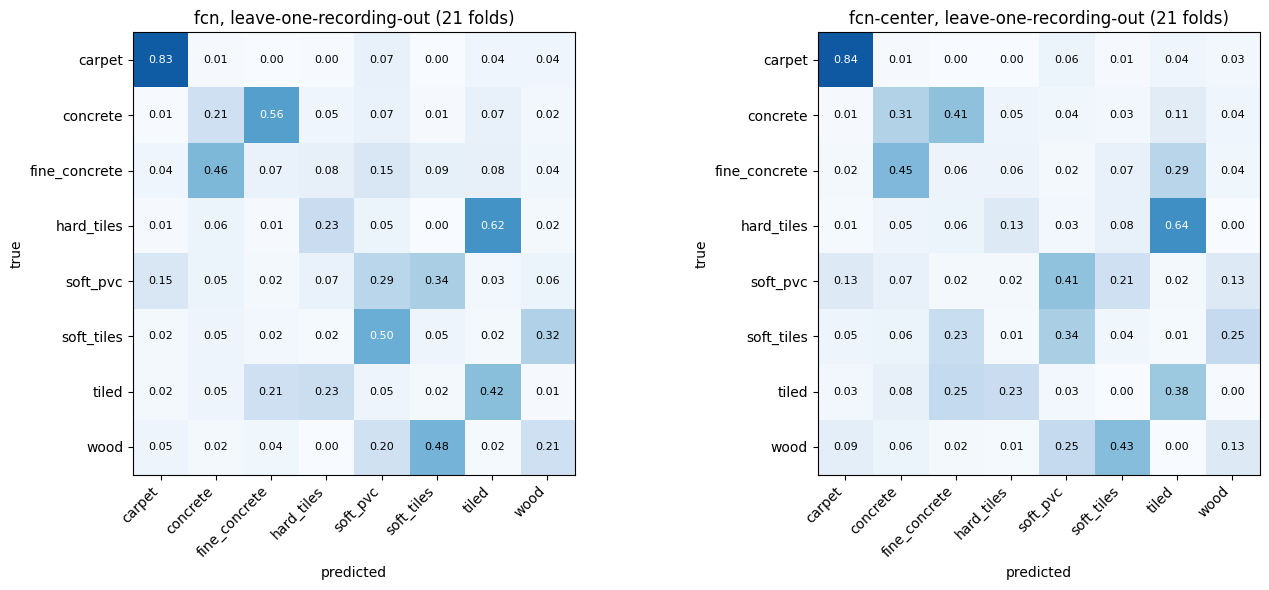

      date owner      model setting fold  macro_f1  accuracy  mode_macro_f1  auroc  fpr95                                                                    note
2026-11-23     C minirocket  8class  all    0.2571    0.2796         0.7163    NaN    NaN aeon MiniRocket 9996 features + Ridge, 6ch, train-rec norm, total 3235s
2026-11-24     C        fcn  8class  all    0.2887    0.3025         0.6983    NaN    NaN             FCN lam=0.0 epochs=69 batch=64 lr=0.001, 6ch, total 18.6min
2026-11-24     C fcn-center  8class  all    0.2816    0.3061         0.6880    NaN    NaN             FCN lam=0.1 epochs=88 batch=64 lr=0.001, 6ch, total 25.1min

↑ Colab 레포는 임시 복사본. 새로 추가된 줄을 로컬 results/results.csv에 붙여 넣고 커밋


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, results):
    cm = confusion_matrix(y, results[name]["pred"], labels=CLASSES, normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(f"{name}, leave-one-recording-out (21 folds)")
plt.tight_layout()
plt.show()

res_csv = pd.read_csv(ROOT / "results" / "results.csv")
print(res_csv[res_csv.owner == "C"].to_string(index=False))
print("\n↑ Colab 레포는 임시 복사본. 새로 추가된 줄을 로컬 results/results.csv에 붙여 넣고 커밋")

### 결과 읽는 법

- `summary_tbl`: macro-F1이 팀 주 지표. MiniRocket(01 노트북)보다 높은지, center loss가 분류 성능을 해치지 않는지
  - center loss의 목적은 분류 향상이 아니라 미등록 판별(D)이다. 분류가 비슷하게 유지되기만 해도 된다
- `per_fold_cmp`: 녹화별로 어느 쪽이 나은지. 특정 재질에서만 차이가 나는지 본다
- 혼동행렬: 모드가 다른 재질끼리의 오류(예: wood ↔ carpet)가 청소에 가장 해롭다

## 6. 임베딩: 재질 하나 빼기 147-fold (D·E 전달용)

fold마다:

1. 빠진 재질의 녹화 전부 + 시험용 녹화 1개를 뺀 나머지로 학습 (재질 7종)
2. 학습 녹화 통계로 **구간 7,626개 전부**를 정규화 → 임베딩 z (7626, 128), logits (7626, 7) 계산
3. 드라이브에 저장. 이미 있는 파일은 건너뛴다 → 끊기면 0~2번 셀과 4번 config 셀을 실행한 뒤 이 셀만 다시 실행

- epoch 수와 λ는 4번에서 고른 값을 그대로 쓴다 (재질이 7종으로 줄어도 다시 튜닝하지 않음)

파일 이름 (README 규칙 + logits 추가)

- `emb_{모델}_{빠진재질}_{fold}.npy`: (7626, 128), 데이터셋 원래 순서
- `logits_{모델}_{빠진재질}_{fold}.npy`: (7626, 7), 열 순서 = 빠진 재질을 뺀 7종의 알파벳 순
- 모델 이름: `fcn`(CE만), `fcn-center`(+center loss)
- 예: `emb_fcn-center_fine_concrete_3.npy`

D가 쓸 때 (`ood.run_heldout`의 `load`):

```python
def load(held_out, fold):
    z = np.load(f"{EMB_DIR}/emb_fcn-center_{held_out}_{fold}.npy")
    logits = np.load(f"{EMB_DIR}/logits_fcn-center_{held_out}_{fold}.npy")
    return z, logits
```

D와 확인할 것: D의 τ는 학습 녹화 안의 검증 녹화로 정하는데, 이 임베딩 모델은 그 검증 녹화로도 학습했다. 그래서 검증 녹화의 거리가 실제보다 가깝게 나와 τ가 빡빡해질 수 있다 (특히 center loss). 시험용 알려진 녹화가 95%보다 훨씬 적게 통과하면 이 때문일 수 있다.

In [12]:
def run_material_out(name, held_outs=None):
    cfg = config[name]
    todo = [s for s in mfolds if held_outs is None or s["held_out"] in held_outs]

    def path(kind, s):
        return OUT_DIR / f"{kind}_{name}_{s['held_out']}_{s['fold']}.npy"

    left = [s for s in todo if not (path("emb", s).exists() and path("logits", s).exists())]
    print(f"[{name}] 전체 {len(todo)}개 중 남은 것 {len(left)}개")
    t_all = time.perf_counter()
    for k, s in enumerate(left, 1):
        tr = np.where(np.isin(rec, s["train"]))[0]
        x_tr, stats = normalize(X[tr])
        classes = sorted(set(y[tr]))                       # 빠진 재질을 뺀 7종
        t0 = time.perf_counter()
        model, h = train_model(to_input(x_tr), y[tr], classes, cfg["lam"], cfg["epochs"])
        sec = time.perf_counter() - t0
        z, l = embed(model, to_input(normalize(X, stats)))  # 7,626개 전부, 원래 순서
        np.save(path("logits", s), l)
        np.save(path("emb", s), z)
        log_train(model=name, split="leave-one-material-out", held_out=s["held_out"], fold=s["fold"],
                  n_train=len(tr), epochs=cfg["epochs"], lam=cfg["lam"], sec=round(sec, 1),
                  sec_per_epoch=round(h.sec.mean(), 3), final_train_ce=round(h.train_ce.iloc[-1], 4),
                  final_train_center=round(h.train_center.iloc[-1], 4))
        eta = (time.perf_counter() - t_all) / k * (len(left) - k)
        print(f"[{name}] {k:3d}/{len(left)} | 빠진 재질 {s['held_out']:<13} fold {s['fold']:2d} "
              f"| {sec:5.1f}초 | 남은 시간 약 {eta / 60:.0f}분")
    print(f"[{name}] 끝")

CE만(`fcn`) 먼저 전부 만든 뒤 center loss(`fcn-center`)를 만든다. D는 `fcn`이 끝나는 대로 B의 MLP 임베딩 자리에 바꿔 끼울 수 있다.

- 일부 재질만 먼저 만들려면: `run_material_out("fcn", held_outs=["carpet"])`

In [ ]:
run_material_out("fcn")

In [17]:
run_material_out("fcn-center")

[fcn-center] 전체 147개 중 남은 것 37개
[fcn-center]   1/37 | 빠진 재질 tiled         fold  0 |  61.3초 | 남은 시간 약 37분
[fcn-center]   2/37 | 빠진 재질 tiled         fold  1 |  58.9초 | 남은 시간 약 35분
[fcn-center]   3/37 | 빠진 재질 tiled         fold  2 |  59.5초 | 남은 시간 약 34분
[fcn-center]   4/37 | 빠진 재질 tiled         fold  3 |  59.9초 | 남은 시간 약 33분
[fcn-center]   5/37 | 빠진 재질 tiled         fold  4 |  60.1초 | 남은 시간 약 32분
[fcn-center]   6/37 | 빠진 재질 tiled         fold  5 |  58.3초 | 남은 시간 약 31분
[fcn-center]   7/37 | 빠진 재질 tiled         fold  6 |  56.7초 | 남은 시간 약 30분
[fcn-center]   8/37 | 빠진 재질 tiled         fold  7 |  60.8초 | 남은 시간 약 29분
[fcn-center]   9/37 | 빠진 재질 tiled         fold  8 |  56.8초 | 남은 시간 약 28분
[fcn-center]  10/37 | 빠진 재질 tiled         fold  9 |  60.9초 | 남은 시간 약 27분
[fcn-center]  11/37 | 빠진 재질 tiled         fold 10 |  60.0초 | 남은 시간 약 26분
[fcn-center]  12/37 | 빠진 재질 tiled         fold 11 |  59.7초 | 남은 시간 약 25분
[fcn-center]  13/37 | 빠진 재질 tiled         fold 12 |  61.2초 | 남은 시간 약 24분
[fcn-center]  14/37

In [18]:
# 저장 파일 확인: 개수와 모양
for name in ["fcn", "fcn-center"]:
    n = sum((OUT_DIR / f"emb_{name}_{s['held_out']}_{s['fold']}.npy").exists() for s in mfolds)
    print(f"{name}: 임베딩 {n}/{len(mfolds)}개")

s = mfolds[0]
z = np.load(OUT_DIR / f"emb_fcn_{s['held_out']}_{s['fold']}.npy")
l = np.load(OUT_DIR / f"logits_fcn_{s['held_out']}_{s['fold']}.npy")
print("예시", s["held_out"], s["fold"], "| z", z.shape, "| logits", l.shape)

fcn: 임베딩 147/147개
fcn-center: 임베딩 147/147개
예시 carpet 0 | z (7626, 128) | logits (7626, 7)


## 7. 진행 기록 정리

`train_log.csv`(드라이브)에 학습 1회마다 한 줄씩 쌓여 있다. 아래 표를 진행 기록에 옮긴다.

In [19]:
log = pd.read_csv(LOG_PATH)
tbl = log.groupby(["model", "split"]).agg(
    runs=("fold", "size"),
    epochs=("epochs", "first"),
    lam=("lam", lambda s: ", ".join(str(v) for v in sorted(s.unique()))),
    sec_per_epoch=("sec_per_epoch", "mean"),
    sec_per_run=("sec", "mean"),
    total_min=("sec", lambda s: s.sum() / 60),
    final_train_ce=("final_train_ce", "mean"),
).round(3)
print(tbl.to_string())
print("\nGPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")

                                    runs  epochs                    lam  sec_per_epoch  sec_per_run  total_min  final_train_ce
model      split                                                                                                              
fcn        leave-one-material-out    193      69                    0.0          0.653       45.053    144.920           0.210
           leave-one-recording-out    84      69                    0.0          0.753       52.014     72.820           0.231
fcn-center leave-one-material-out    383      69             0.001, 0.1          0.702       53.598    342.132           0.201
           leave-one-recording-out    72      69             0.001, 0.1          0.805       60.078     72.093           0.219
fcn-tuning inner-validation           24     100  0.0, 0.001, 0.01, 0.1          0.394       49.042     19.617           0.184

GPU: Tesla T4


### 진행 기록에 적을 것

- 모델: FCN(128·256·128 필터, 길이 8·5·3, BN+ReLU, 전역 평균 풀링), 파라미터 수
- 학습: Adam lr 0.001, 배치 64, epoch 수, λ, α = 0.5, seed 42, 증강 없음, 6채널, 학습 녹화 기준 정규화
- 튜닝: 튜닝 fold 6개 × λ 4개, 고른 epoch·λ와 그 근거(곡선)
- 시간: 1 epoch 초, 학습 1회 초, 단계별 총 시간과 학습 횟수 (위 표), GPU 종류
- 결과: fcn / fcn-center의 macro-F1·정확도·모드 macro-F1·모드 정확도, MiniRocket과 비교
- 눈에 띈 것: 정확도가 낮은 녹화, 혼동 쌍, center loss로 달라진 재질
- 전달: 임베딩 저장 위치와 개수, D에게 알린 날짜